In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
voo = pd.read_excel("VOO Monthly.xlsx")

In [3]:
voo.head()
voo.columns
voo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 3 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    122 non-null    datetime64[ns]
 1   Total Net Assets as of Month End        122 non-null    float64       
 2   Total Return per Share as of Month End  122 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 3.0 KB


In [4]:
voo = voo.rename(columns={
    "Date": "date",
    "Total Net Assets as of Month End": "tna",
    "Total Return per Share as of Month End": "ret"
})

In [5]:
voo["ret"].describe()

count    122.000000
mean       0.012193
std        0.043372
min       -0.123811
25%       -0.008549
50%        0.019179
75%        0.036945
max        0.128200
Name: ret, dtype: float64

In [6]:
voo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    122 non-null    datetime64[ns]
 1   tna     122 non-null    float64       
 2   ret     122 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 3.0 KB


In [7]:
voo["tna_lag"] = voo["tna"].shift(1)

voo["net_flow"] = voo["tna"] - (voo["tna_lag"] * (1 + voo["ret"]))

voo["flow_voo"] = voo["net_flow"] / voo["tna_lag"]

voo = voo.dropna()

In [8]:
voo["ret"].describe()

count    121.000000
mean       0.012269
std        0.043544
min       -0.123811
25%       -0.009078
50%        0.019431
75%        0.036980
max        0.128200
Name: ret, dtype: float64

In [9]:
voo[["tna", "ret", "net_flow", "flow_voo"]].head()
voo["flow_voo"].describe()

count    121.000000
mean       0.014368
std        0.016354
min       -0.036348
25%        0.005694
50%        0.014960
75%        0.021176
max        0.064238
Name: flow_voo, dtype: float64

In [10]:
voo_flow = voo[["date", "flow_voo"]]

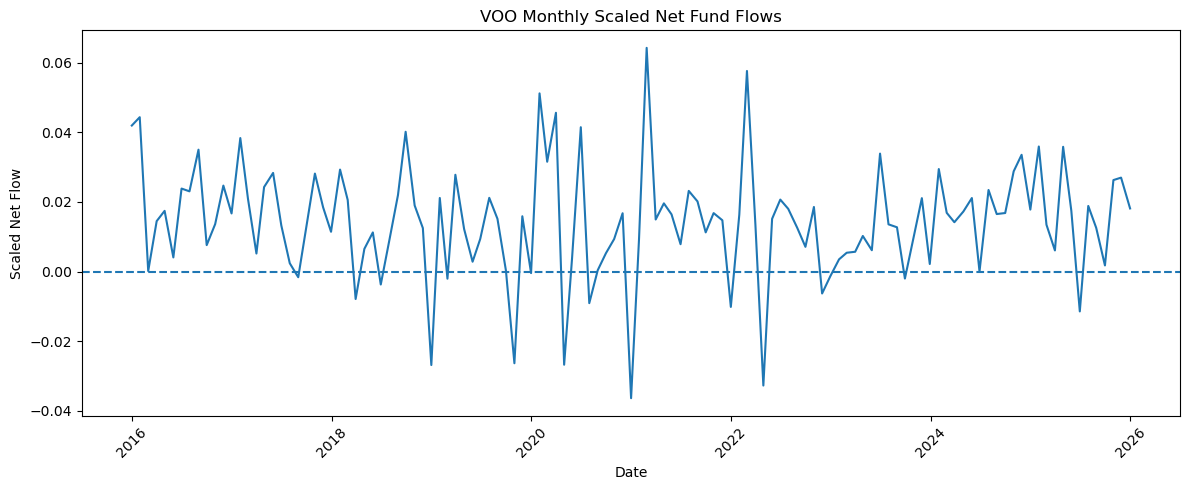

In [11]:
plt.figure(figsize=(12,5))

plt.plot(voo["date"], voo["flow_voo"])
plt.axhline(0, linestyle="--")

plt.title("VOO Monthly Scaled Net Fund Flows")
plt.xlabel("Date")
plt.ylabel("Scaled Net Flow")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [12]:
voo[["date", "flow_voo"]].head()

,date,flow_voo
1,2015-12-31,0.041933
2,2016-01-29,0.044331
3,2016-02-29,0.000162
4,2016-03-31,0.014497
5,2016-04-29,0.017441


In [13]:
voo = voo.copy()

voo["date"] = pd.to_datetime(voo["date"])
voo["date"] = voo["date"] + pd.offsets.MonthEnd(0)

In [14]:
voo[["date", "flow_voo"]].head()

,date,flow_voo
1,2015-12-31,0.041933
2,2016-01-31,0.044331
3,2016-02-29,0.000162
4,2016-03-31,0.014497
5,2016-04-30,0.017441


In [15]:
voo_final = voo[["date", "flow_voo"]].copy()
voo_final = voo_final.sort_values("date")

voo_final.to_csv("voo_clean.csv", index=False)